# Some code that illustrates Monte Carlo integration

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import scipy.integrate as integrate
from scipy.stats import lognorm

In [5]:
def u(c,r):
    """
    CRRA class of utility functions
    r is the measure of relative risk aversion
    """
    if r == 1:
        u=np.log(c)
        return u
    u = (c**(1-r) - 1)/(1-r)
    return u
    

In [6]:
def cert(u,r):
    """
    inverts CRRA class of utility functions
    r is the measure of relative risk aversion
    """
    if r == 1:
        cert=np.exp(u)
        return cert
    cert = (u*(1-r)+1)**(1/(1-r))
    return cert
    

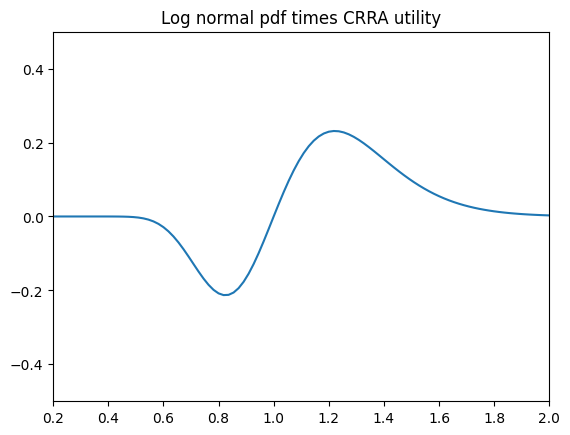

In [16]:
#A common parametrization for a lognormal random variable Y is in terms of the mean, mu, 
#and standard deviation, sigma, of the unique normally distributed random variable X such that exp(X) = Y. 
#This parametrization corresponds to setting s = sigma and scale = exp(mu).
# loc is a shift in the origin

r=3  #expected utility parameter
xmin=0.2
xmax=2
ymax=0.5
ymin=-0.5
n=100
x0 = np.linspace(xmin, xmax, n)

plt.plot(x0, u(x0,r)*lognorm.pdf(x0, loc=0, s=0.195, scale=np.exp(0.084))) 


plt.xlim([xmin,xmax])
plt.ylim([ymin, ymax])
plt.title('Log normal pdf times CRRA utility')
plt.show()

# Example of MC integration

In [25]:
N=100_000
r=3
from scipy.stats import uniform
x = xmin+(xmax-xmin)*uniform.rvs(size=N) #uniformly distributed
y=u(x,r)*lognorm.pdf(x, loc=0, s=0.195, scale=np.exp(0.084)) #utility of x times the pdf at x
z=(xmax-xmin)*y.mean()  #need to integrate over an appropriate segment
print("The expected utility of holding the market portfolio is", np.around(z,3))

The expected utility of holding the market portfolio is 0.044


# ChatGPT wrote this next cell

In [29]:
r=3

N = 100_000
a, b = 0.2, 2

mu = 0.084
sigma = 0.195

# Uniform Monte Carlo draws over the interval of integration
x = np.random.uniform(a, b, N)

# Evaluate the lognormal density at those points
f = u(x,r)*lognorm.pdf(x, s=sigma, scale=np.exp(mu))

# Monte Carlo approximation to the integral
integral = (b-a) * np.mean(f)

print("Monte Carlo estimate =", np.around(integral,3))

Monte Carlo estimate = 0.044


## What is the certainty equivalent of this lottery?

In [20]:
r=3
np.around(cert(z,r),3)

np.float64(1.045)

## Another example of MC integration, with greater risk aversion

In [21]:
r=8
xmin=0.2
xmax=2

N=100_000
x=lognorm.rvs(loc=0, s=0.195, scale=np.exp(0.084),size=N) 
y=u(x,r)
y.mean()

np.float64(-0.05799495143510085)

In [23]:
r=8
np.around(cert(y.mean(),r),3)

np.float64(0.952)

# More examples of Monte Carlo integration

Crude example, like throwing darts

My guess of π is 3.2
My guess of π is 3.4
My guess of π is 3.124
My guess of π is 3.1488
My guess of π is 3.14688
My guess of π is 3.143632


[]

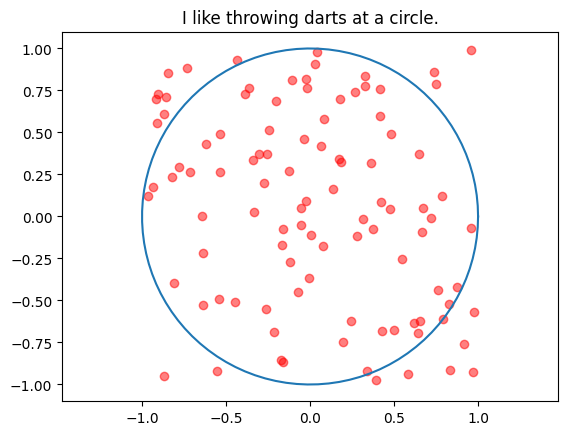

In [13]:
D=100
θ = np.linspace(0, 2*np.pi, D)

a,b=-1,1


for n in [10, 100, 1_000, 10_000, 100_000, 1_000_000]:
    pts = np.random.uniform(0,1,(n, 2))
    y=pts[:, 1]*(b-a)+a
    x=pts[:,0]*(b-a)+a
    print("My guess of π is", 4*sum((x**2+y**2)<=1)/len(x))
    
n=100
pts = np.random.uniform(0,1,(n, 2))
y=pts[:, 1]*(b-a)+a
x=pts[:,0]*(b-a)+a
plt.plot(np.cos(θ),np.sin(θ))
plt.scatter(x, y, c="red", alpha=0.5)

plt.xlim(-1.05, 1.05)
plt.ylim(-1.05, 1.05)
plt.axis("equal")

plt.title("I like throwing darts at a circle.")
plt.plot()

A little smarter, now.

In [14]:
import numpy as np
np.random.seed(1234)
a,b,N=0,1,100_000
x=np.random.uniform(a,b,N)
def f(x):
    return np.sqrt(1-x**2)
4*(b-a)*f(x).mean()

np.float64(3.141044268119065)

Now, even better?

In [15]:
from scipy.stats import truncnorm
a,b,N=0,1,100_000
x=truncnorm.rvs(a,b,size=N)
def f(x):
    return np.sqrt(1-x**2)/truncnorm(a,b).pdf(x)
4*f(x).mean()

np.float64(3.144233143737618)

## When Uniform Monte Carlo Is Inefficient

Consider the function

$$
f_\epsilon(x)=
\begin{cases}
\dfrac{1}{2\epsilon}, & |x|\leq \epsilon,\\
0, & |x|>\epsilon,
\end{cases}
\qquad -1\leq x\leq 1.
$$

The function is zero almost everywhere, but has a narrow spike around zero.

Its integral is exactly

$$
\int_{-1}^1 f_\epsilon(x)\,dx
=
(2\epsilon)\frac{1}{2\epsilon}
=1.
$$

If $\epsilon$ is very small, uniform Monte Carlo sampling is potentially
very inefficient because almost all of our random draws occur where the
function is zero.

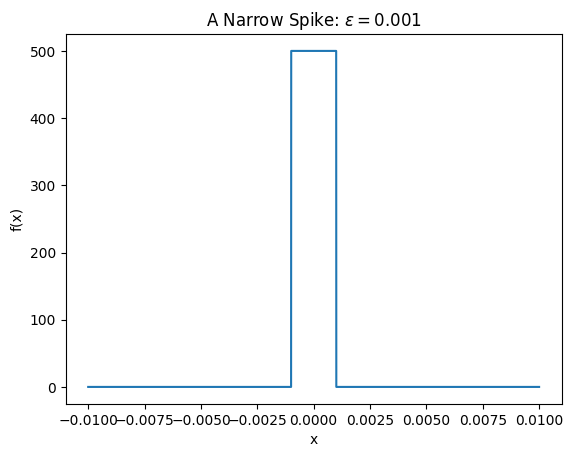

In [30]:
import numpy as np
import matplotlib.pyplot as plt

epsilon = 0.001

def f(x):
    return np.where(np.abs(x) <= epsilon,
                    1/(2*epsilon),
                    0)

x_grid = np.linspace(-0.01, 0.01, 10_000)

plt.plot(x_grid, f(x_grid))
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title(rf"A Narrow Spike: $\epsilon={epsilon}$")
plt.show()

### Uniform Monte Carlo

Suppose

$$
X_i\sim U(-1,1).
$$

Then

$$
\int_{-1}^1 f(x)\,dx
=
2E[f(X)].
$$

Hence the Monte Carlo estimator is

$$
\widehat I_N
=
\frac{2}{N}\sum_{i=1}^N f(X_i).
$$

But a uniform draw lands inside the spike with probability only

$$
P(|X|\leq\epsilon)=\epsilon.
$$

Thus the expected number of observations that actually hit the spike is

$$
N\epsilon.
$$

When $\epsilon=0.001$ and $N=1000$, we expect only **one useful
observation** out of 1000 draws.

In [34]:
np.random.seed(1235)

N = 1000

x = np.random.uniform(-1, 1, N)

hits = np.sum(np.abs(x) <= epsilon)
estimate = 2 * f(x).mean()

print("True integral =", 1)
print("Monte Carlo estimate =", estimate)
print("Number of draws hitting the spike =", hits)
print("Expected number of hits =", N*epsilon)

True integral = 1
Monte Carlo estimate = 0.0
Number of draws hitting the spike = 0
Expected number of hits = 1.0


# Important Weakness

This illustrates an important weakness of naive Monte Carlo integration.

The estimator is still valid, but we are sampling very inefficiently:
almost all of our computational effort is spent evaluating the function
where it is zero.

This suggests a better strategy:

> **Sample more frequently from regions that make large contributions to
> the integral.**

This is the basic idea behind **importance sampling**.

Mean estimate = 0.998
Standard deviation = 0.9838678773087369


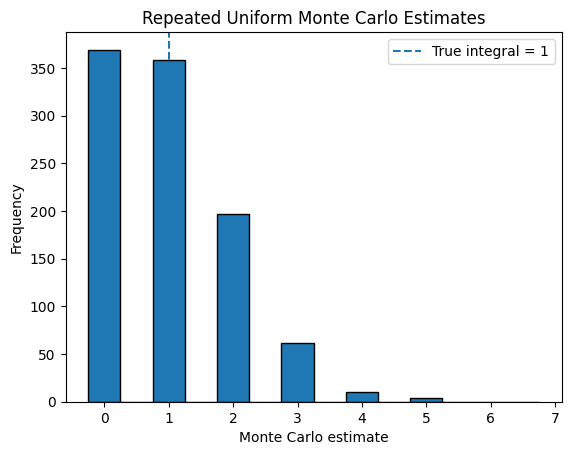

In [35]:
np.random.seed(1234)

M = 1000       # number of Monte Carlo experiments
N = 1000       # draws in each experiment

estimates = np.empty(M)

for j in range(M):
    x = np.random.uniform(-1, 1, N)
    estimates[j] = 2 * f(x).mean()

print("Mean estimate =", estimates.mean())
print("Standard deviation =", estimates.std())

plt.hist(estimates, bins=np.arange(-0.25, 7.25, 0.5),
         edgecolor="black")
plt.axvline(1, linestyle="--", label="True integral = 1")
plt.xlabel("Monte Carlo estimate")
plt.ylabel("Frequency")
plt.title("Repeated Uniform Monte Carlo Estimates")
plt.legend()
plt.show()

Mean estimate = 1.0183000000000002
Standard deviation = 0.3207415002770923


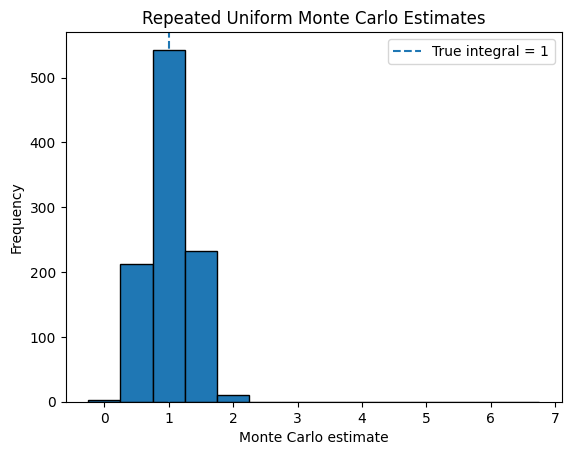

In [37]:
np.random.seed(1234)

M = 1000       # number of Monte Carlo experiments
N = 1000       # draws in each experiment
over_sample = 0.1

estimates = np.empty(M)

for j in range(M):
    x = np.random.uniform(-over_sample, over_sample, N)
    estimates[j] = 2 * over_sample* f(x).mean()

print("Mean estimate =", estimates.mean())
print("Standard deviation =", estimates.std())

plt.hist(estimates, bins=np.arange(-0.25, 7.25, 0.5),
         edgecolor="black")
plt.axvline(1, linestyle="--", label="True integral = 1")
plt.xlabel("Monte Carlo estimate")
plt.ylabel("Frequency")
plt.title("Repeated Uniform Monte Carlo Estimates")
plt.legend()
plt.show()

# Further reading

https://www.scratchapixel.com/lessons/mathematics-physics-for-computer-graphics/monte-carlo-methods-in-practice/monte-carlo-integration.html